# Band noise NEL MODELLO di analisi: simulazioni

Dati simulati con band noise LOFAR a **50 componenti** (`Simulations_bandnoise_A1xx_sv44.ipynb`), ora analizzati
con un modello a **8 parametri**: i 6 standard (alpha = 4.4) + `band_noise_log10_A` e `band_noise_gamma`
sui backend LOFAR, sempre a 50 componenti.

Domande:
1. il band noise iniettato viene recuperato?
2. il bias sugli altri parametri visto con il modello a 6 parametri (notebook 16, 17, 18) sparisce?

Prior del band noise: le stesse degli altri processi power-law (Iraci et al. 2025, Tab. A.1):
log10_A ~ U(-20, -11), gamma ~ U(0, 7).

Questo notebook contiene per ora solo **A140** (band noise iniettato a log10_A = -14).

## Setup comune

In [1]:
import numpy as np
import os, glob, json
import pickle

import sys

# this is the path to the discovery folder
sys.path.insert(0, "./")
import discovery_new as ds

import matplotlib.pyplot as plt
import scipy
import jax.numpy as jnp

from scipy.stats import uniform
import re
from PTMCMCSampler.PTMCMCSampler import PTSampler as ptmcmc
import jax

import time
import emcee
import corner

Optional mpi4py package is not installed.  MPI support is not available.


In [2]:
##### Cell for the prior distributions ###################################################################################

my_priordict = {}
my_priordict["(.*_)?sv_gp_gamma.*"] = [0, 7]
my_priordict["(.*_)?sv_gp_alpha.*"] = [0, 10]
my_priordict["(.*_)?sv_gp_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?sw_log10_A.*"] = [-10, 1]
my_priordict["(.*_)?sw_gamma.*"] = [-5, 6]
my_priordict["(.*_)?dm_gp_gamma.*"] = [0, 7]
my_priordict["(.*_)?dm_gp_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?red_noise_gamma.*"] = [0, 7]
my_priordict["(.*_)?red_noise_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?sw_n_earth.*"] = [0, 30]
# band noise: stesse prior degli altri processi power-law
my_priordict["(.*_)?band_noise_gamma.*"] = [0, 7]
my_priordict["(.*_)?band_noise_log10_A.*"] = [-20, -11]


def build_priors(param_names, priordict):
    """
    Build a {param_name: scipy dist} dict with uniform prior distributions in the range
    """
    priors = {}
    unmatched = []
    for name in param_names:
        matched = False
        for pattern, (lo, hi) in priordict.items():
            if re.fullmatch(pattern, name):
                priors[name] = uniform(loc=lo, scale=hi - lo)
                matched = True
                break
        if not matched:
            unmatched.append(name)

    if unmatched:
        print(f"Warning: no prior found for {len(unmatched)} parameters, "
              f"falling back to standard normal:\n  {unmatched}")
    return priors

## Modello di analisi

Una sola funzione costruisce il modello per tutte le ampiezze: cambia solo la pulsar simulata che le si passa.
Con `band_noise=False` restituisce il modello standard a 6 parametri (serve solo per avere l ordine dei
parametri delle catene a 6 par, nel confronto finale).

In [3]:
def costruisci_modello(p, band_noise=True, components_bn=50):
    # data
    model = [p.residuals]
    # timing model
    model += [ds.makegp_timing(p, svd=True)]
    # white noise parameters
    model += [ds.makenoise_measurement(p, p.noisedict, tnequad=True, ecorr=True)]
    # red noise parameters
    model.append(ds.makegp_fourier(p, ds.powerlaw, p.noisedict[p.name + '_red_components'], T=ds.getspan(p), name='red_noise'))
    # DM variation parameters
    model.append(ds.makegp_fourier(p, ds.powerlaw, p.noisedict[p.name + '_dm_components'], T=ds.getspan(p), name='dm_gp',
                                   fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
    # scattering noise parameters (alpha = 4.4, come nella simulazione)
    model.append(ds.makegp_fourier(p, ds.powerlaw, p.noisedict[p.name + '_chrom_components'], T=ds.getspan(p), name='sv_gp',
                                   fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))
    # band noise sui backend LOFAR
    if band_noise:
        model.append(ds.makegp_fourier_select(p, ds.powerlaw, components=components_bn, T=ds.getspan(p),
                                              name='band_noise', selection=ds.lofar_backends))
    return model

# A140: band noise iniettato a log10_A = -14

Dati: `sim_data_noise_bn_A140_sv44prova_con50/`.

In [4]:
bn140_psr = ds.pulsar.Pulsar.read_feather('sim_data_noise_bn_A140_sv44prova_con50/J1640+2224')

# valori veri iniettati
truths_bn140 = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
    'J1640+2224_band_noise_gamma': 3.0,
    'J1640+2224_band_noise_log10_A': -14.0,
}

## Modello a 8 parametri

In [5]:
logL_bn140 = ds.PulsarLikelihood(costruisci_modello(bn140_psr)).logL

# controllo: 8 parametri, gli stessi dei valori veri
assert set(logL_bn140.params) == set(truths_bn140.keys())
logL_bn140.params

['J1640+2224_band_noise_gamma',
 'J1640+2224_band_noise_log10_A',
 'J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [6]:
def params_dict_from_array_bn140(x):
    x = np.asarray(x)
    return dict(zip(logL_bn140.params, x))

priors_bn140 = build_priors(logL_bn140.params, my_priordict)   # nessun warning atteso

def log_prior_bn140(x):
    params = params_dict_from_array_bn140(x)
    logp = 0.0
    for name, value in params.items():
        logp += priors_bn140[name].logpdf(value)
    return logp

def prior_draw_bn140():
    return np.array([priors_bn140[name].rvs() for name in logL_bn140.params])

x0_bn140 = prior_draw_bn140()
x0_bn140

array([  2.11151051, -18.40019873,   5.77523349, -19.78590215,
         5.23453907, -17.42288561,   2.51154194, -16.89349526])

In [7]:
@jax.jit
def _jit_logL_bn140(params_array):
    return logL_bn140(dict(zip(logL_bn140.params, params_array)))

def log_likelihood_bn140(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_bn140(jnp.array(x))))

print('logL iniziale =', log_likelihood_bn140(x0_bn140))

# tempo di una valutazione, per stimare la durata del sampling
start = time.time()
for _ in range(20):
    log_likelihood_bn140(x0_bn140)
dt = (time.time() - start) / 20
print(f'una valutazione = {dt*1e3:.1f} ms  ->  10^6 iterazioni ~ {dt*1e6/3600:.1f} ore')

logL iniziale = 67775.15391166453
una valutazione = 1.9 ms  ->  10^6 iterazioni ~ 0.5 ore


In [8]:
sampler_bn140 = ptmcmc(
    ndim=len(logL_bn140.params),
    logl=log_likelihood_bn140,
    logp=log_prior_bn140,
    cov=np.eye(len(logL_bn140.params)) * 0.001,
    outDir='./test_sim_bn_A140_bnmodel/',
    resume=True
)

### Sampling

Eseguire **una sola volta**; poi per rifare i grafici ripartire dalla cella che legge `chain_1.txt`.

In [10]:
ESEGUI_SAMPLING_A140 = True   # True solo per lanciare davvero il campionamento

if ESEGUI_SAMPLING_A140:
    sampler_bn140.sample(x0_bn140, Niter=1000000, thin=10)

Finished 1.00 percent (1.00 percent of new work) in 21.192705 s Acceptance rate = 0.2834Adding DE jump with weight 20
Finished 100.00 percent (100.00 percent of new work) in 2000.998946 s Acceptance rate = 0.253501
Run Complete


## Catena e risultati

In [11]:
chain_bn140 = np.loadtxt('./test_sim_bn_A140_bnmodel/chain_1.txt')
chain_bn140 = chain_bn140[len(chain_bn140)//4:, :-4]   # 25% di burn-in, via le 4 colonne diagnostiche

tau = emcee.autocorr.integrated_time(chain_bn140, has_walkers=False, quiet=True)
print('campioni         =', len(chain_bn140))
print('tau              =', np.round(tau, 1))
print('Effective sample size =', int(len(chain_bn140) / tau.max()))

idx_bn140 = {name: i for i, name in enumerate(logL_bn140.params)}

campioni         = 75001
tau              = [10.2 10.   9.8  9.6 10.8  4.6  8.4  7.5]
Effective sample size = 6945


In [12]:
# distanza dal valore vero in unita di sigma della posteriore
for name in logL_bn140.params:
    q16, q50, q84 = np.percentile(chain_bn140[:, idx_bn140[name]], [16, 50, 84])
    shift = (q50 - truths_bn140[name]) / (0.5 * (q84 - q16))
    print(f"{name.replace('J1640+2224_', ''):22s} vero {truths_bn140[name]:8.3f}   mediana {q50:8.3f}   shift {shift:6.2f} sigma")

band_noise_gamma       vero    3.000   mediana    3.203   shift   0.09 sigma
band_noise_log10_A     vero  -14.000   mediana  -16.652   shift  -1.14 sigma
dm_gp_gamma            vero    6.471   mediana    5.358   shift  -0.95 sigma
dm_gp_log10_A          vero  -15.723   mediana  -15.080   shift   1.26 sigma
red_noise_gamma        vero    0.132   mediana    0.495   shift   1.04 sigma
red_noise_log10_A      vero  -13.213   mediana  -13.189   shift   0.32 sigma
sv_gp_gamma            vero    1.326   mediana    1.275   shift  -0.24 sigma
sv_gp_log10_A          vero  -15.888   mediana  -15.934   shift  -1.04 sigma


### Corner a 8 parametri

In nero i valori veri iniettati.

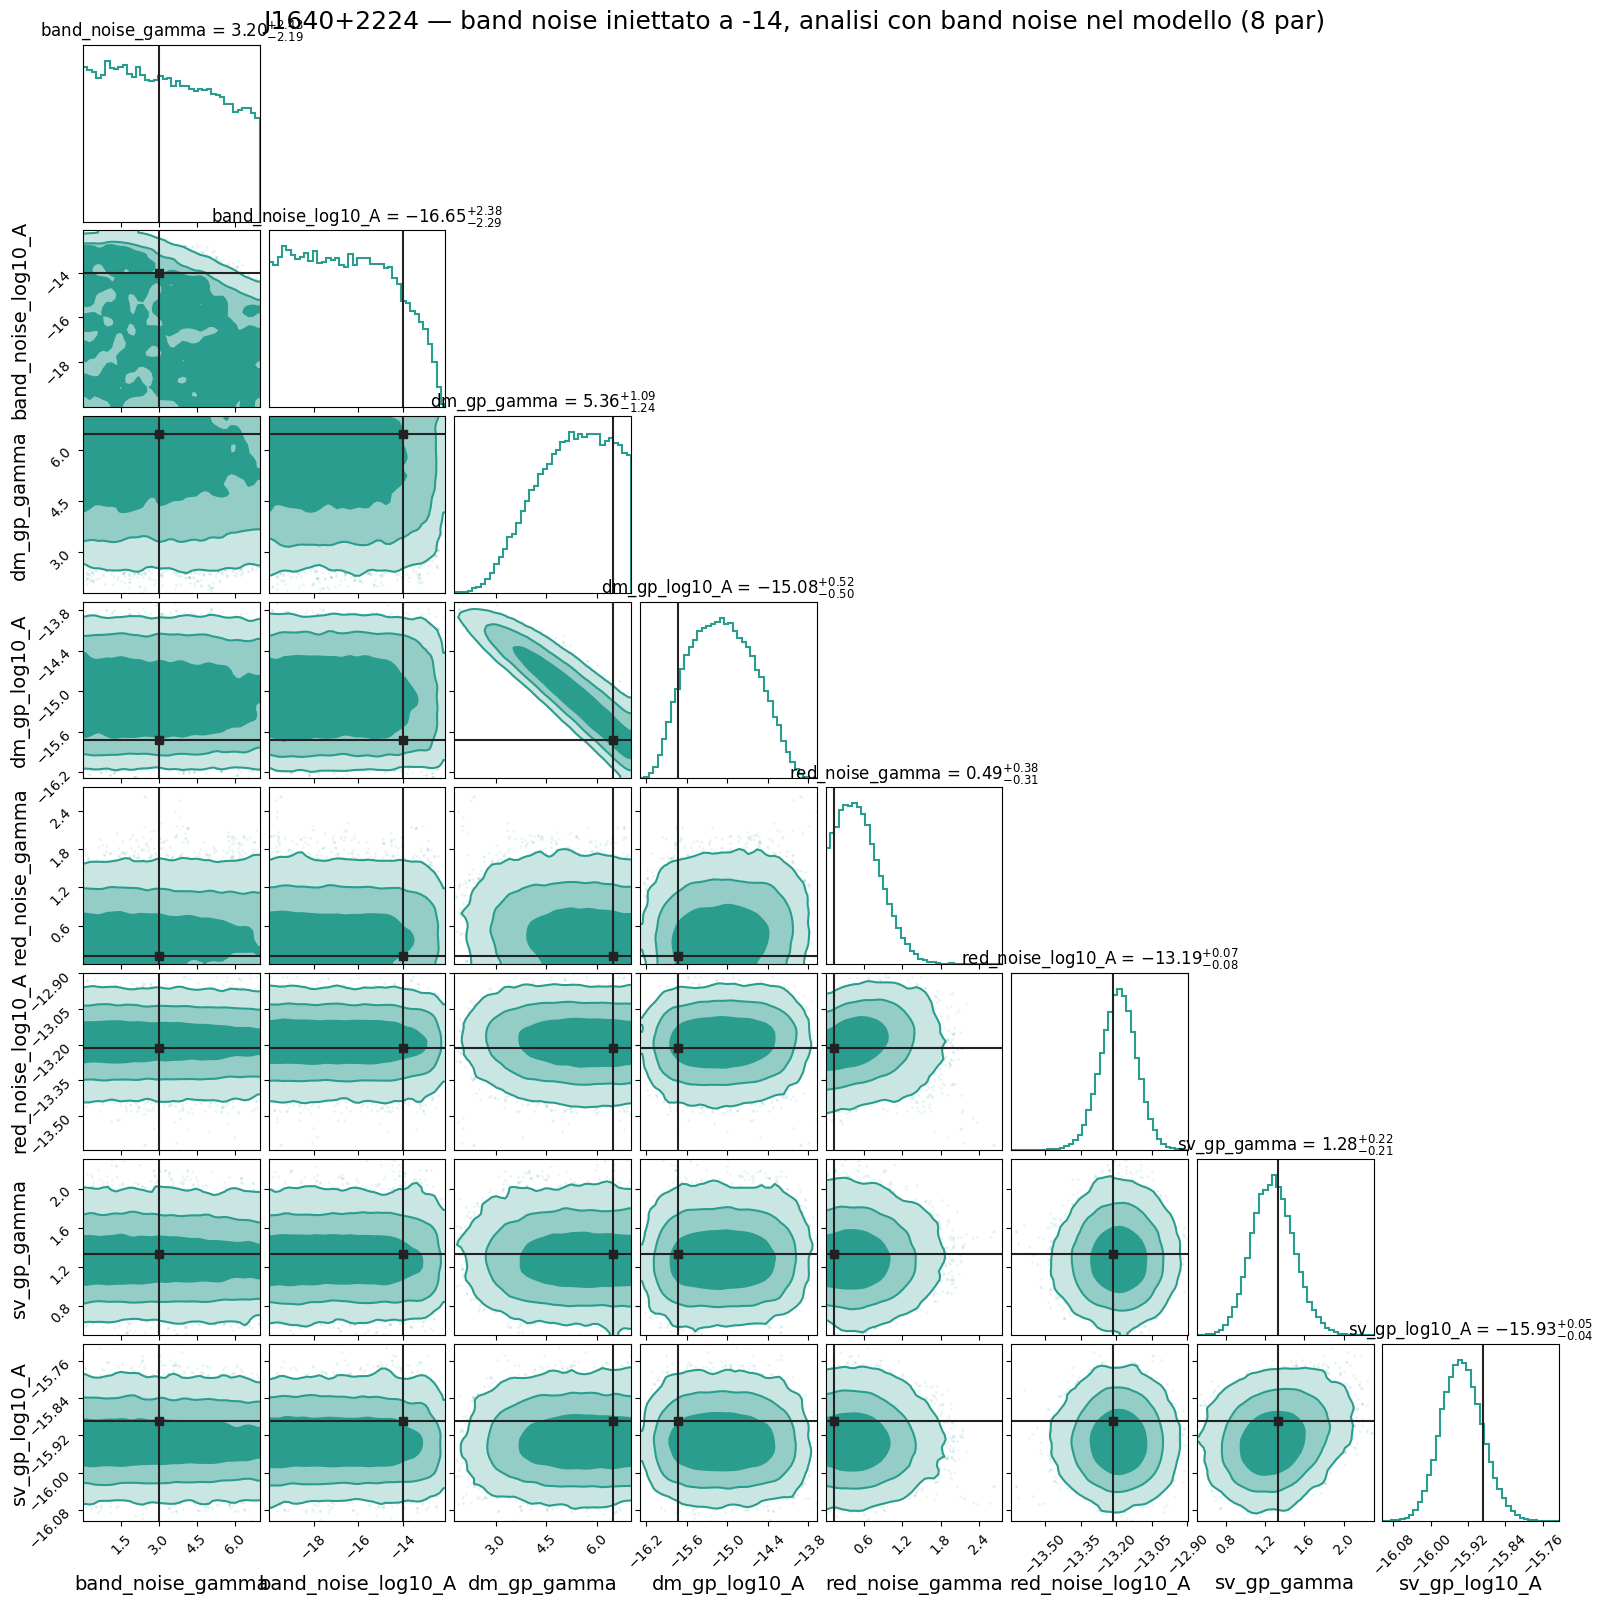

In [13]:
# Etichette pulite (senza il prefisso del pulsar)
clean_labels_bn140 = [name.replace('J1640+2224_', '') for name in logL_bn140.params]
truth_values_bn140 = [truths_bn140[name] for name in logL_bn140.params]

fig = corner.corner(
    chain_bn140,
    labels=clean_labels_bn140,
    truths=truth_values_bn140,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5, "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band noise iniettato a -14, analisi con band noise nel modello (8 par)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A140_bnmodel.png', dpi=150, bbox_inches='tight')

### Confronto: modello a 6 par vs modello a 8 par, sugli stessi dati

La catena a 6 parametri e quella della sezione a 50 componenti del notebook 16
(`test_sim_bn_A140_50comp/`): stessi dati, ma senza band noise nel modello.
Il confronto e sui 6 parametri comuni.

In [14]:
chain_bn140_6par = np.loadtxt('./test_sim_bn_A140_50comp/chain_1.txt')
chain_bn140_6par = chain_bn140_6par[len(chain_bn140_6par)//4:, :-4]

# ordine dei parametri della catena a 6 par = quello del modello standard
params_6par = ds.PulsarLikelihood(costruisci_modello(bn140_psr, band_noise=False)).logL.params

# dalla catena a 8 par prendo solo le 6 colonne comuni, nello stesso ordine
chain_bn140_comuni = chain_bn140[:, [idx_bn140[name] for name in params_6par]]

clean_labels_6par = [name.replace('J1640+2224_', '') for name in params_6par]
truth_values_6par = [truths_bn140[name] for name in params_6par]

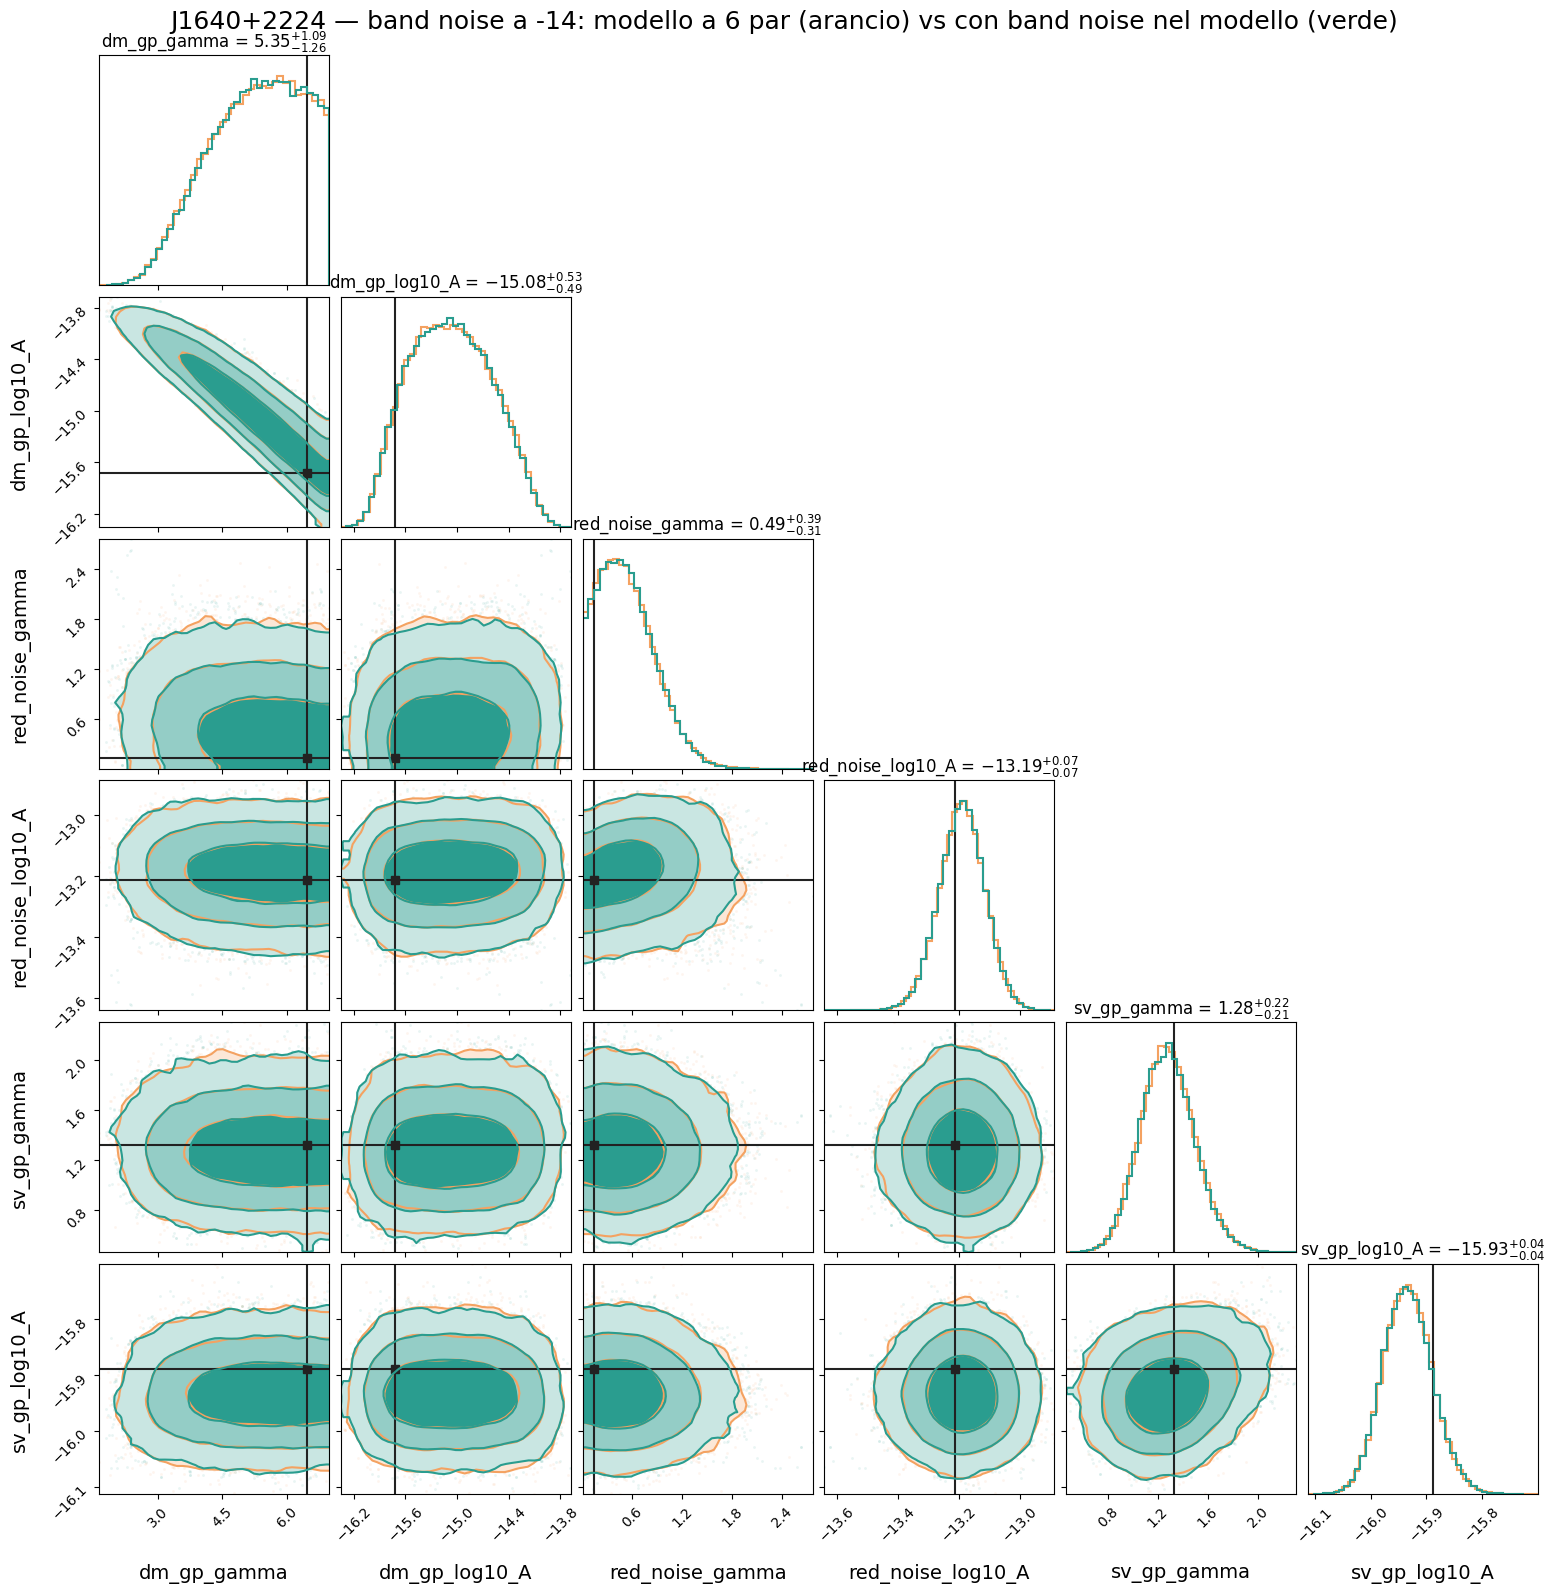

In [15]:
# Primo corner: modello a 6 par (senza band noise) in arancio
fig = corner.corner(
    chain_bn140_6par,
    labels=clean_labels_6par,
    truths=truth_values_6par,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#F4A261',
    hist_kwargs={'color': '#F4A261', 'linewidth': 1.5, "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner: modello a 8 par (con band noise) in verde, sovrapposto
corner.corner(
    chain_bn140_comuni,
    labels=clean_labels_6par,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5, "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band noise a -14: modello a 6 par (arancio) vs con band noise nel modello (verde)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A140_6par_vs_8par.png', dpi=150, bbox_inches='tight')